# Analysis project 2
All results come from the Modal runs in `results/project2/modal/` (3 seeds × 5 folds per configuration).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

MODAL_DIR = Path("../results/project2/modal")
PROJECT1_CV = 0.5548    # project 1 best system (MLP + indicator), CV accuracy

# load every configuration (skip files that are not a CV run, such as test_final.json)
runs = {}
for p in sorted(MODAL_DIR.glob("*.json")):
    r = json.loads(p.read_text())
    if "accuracies" in r and "config" in r and p.stem != "test_final":
        runs[p.stem] = r

def config_row(name, r):
    """One readable table row per configuration."""
    c, e, o = r["config"], r["config"]["enc_kwargs"], r["config"]["opt_kwargs"]
    acc = np.array(r["accuracies"])                     # shape [3 seeds, 5 folds]
    is_lstm = c["enc_type"] == "lstm"
    return {
        "config": name,
        "model": "LSTM" if is_lstm else "embed-and-pool",
        "embeddings": "fastText 300d" if c["emb"] == "fasttext300" else "GloVe 50d",
        "emb": "frozen" if e["freeze_embeddings"] else "trainable",
        "data": f"{int(c['train_fraction'] * 100)}%",
        "lstm hidden": e.get("hidden_size") if is_lstm else "-",
        "pooling": "-" if is_lstm else ("sum" if e.get("average_pool") is False else "mean"),
        "lr": o["learning_rate"],
        "epochs": o["num_epochs"],
        "mean": acc.mean(),
        "std": acc.std(),
        "median best epoch": np.median(np.array(r["best_epochs"])),
    }

all_configs = (pd.DataFrame([config_row(n, r) for n, r in runs.items()])
               .sort_values("mean", ascending=False).reset_index(drop=True))
print(f"{len(all_configs)} configurations loaded")

32 configurations loaded


In [4]:
# Data size: same groups as the plot in project2.ipynb (100% = the base config of each group)
datasize_groups = {
    ("embed-and-pool", "GloVe 50d, frozen"):        ["datasize-pool-frozen-0.1", "datasize-pool-frozen-0.25", "datasize-pool-frozen-0.5", "datasize-pool-frozen-1.0"],
    ("embed-and-pool", "GloVe 50d, trainable"):     ["datasize-pool-trainable-0.1", "datasize-pool-trainable-0.25", "datasize-pool-trainable-0.5", "pool-base"],
    ("embed-and-pool", "fastText 300d, trainable"): ["r2-ft-datasize-pool-0.1", "r2-ft-datasize-pool-0.25", "r2-ft-datasize-pool-0.5", "emb-pool-fasttext300"],
    ("LSTM", "GloVe 50d, frozen"):                  ["datasize-lstm-frozen-0.1", "datasize-lstm-frozen-0.25", "datasize-lstm-frozen-0.5", "lstm-base"],
    ("LSTM", "GloVe 50d, trainable"):               ["datasize-lstm-trainable-0.1", "datasize-lstm-trainable-0.25", "datasize-lstm-trainable-0.5", "datasize-lstm-trainable-1.0"],
    ("LSTM", "fastText 300d, frozen"):              ["r2-ft-datasize-lstm-0.1", "r2-ft-datasize-lstm-0.25", "r2-ft-datasize-lstm-0.5", "emb-lstm-fasttext300"],
}

def datasize_table(model):
    """Mean validation accuracy per share of training data, for one model type."""
    rows = []
    for (m, setup), names in datasize_groups.items():
        if m != model:
            continue
        row = {"setup": setup}
        for frac, name in zip(["10%", "25%", "50%", "100%"], names):
            row[frac] = np.array(runs[name]["accuracies"]).mean()
        rows.append(row)
    return pd.DataFrame(rows).round(4)

## Question 3: Embed-and-pool

In [8]:
cols = ["config", "embeddings", "emb", "pooling", "lr", "epochs", "mean", "std", "median best epoch"]
q3 = all_configs[(all_configs["model"] == "embed-and-pool") & (all_configs["data"] == "100%")][cols]

print(f"Embed-and-pool, full training data (project 1 CV: {PROJECT1_CV})")
display(q3.round(4).reset_index(drop=True))

Embed-and-pool, full training data (project 1 CV: 0.5548)


,config,embeddings,emb,pooling,lr,epochs,mean,std,median best epoch
0,emb-pool-fasttext300,fastText 300d,trainable,mean,0.0010,35,0.5776,0.0188,3.0
1,r2-ft-pool-lr3e-4,fastText 300d,trainable,mean,0.0003,35,0.5710,0.0242,8.0
2,r2-ft-pool-frozen,fastText 300d,frozen,mean,0.0010,35,0.5547,0.0099,33.0
3,pool-base,GloVe 50d,trainable,mean,0.0010,35,0.5509,0.0179,22.0
4,pool-sum,GloVe 50d,trainable,sum,0.0010,35,0.5436,0.0193,25.0
5,datasize-pool-frozen-1.0,GloVe 50d,frozen,mean,0.0010,35,0.3980,0.0130,30.0


In [5]:
print("Embed-and-pool: mean validation accuracy by share of training data per fold (validation fold always complete)")
display(datasize_table("embed-and-pool"))

Embed-and-pool: mean validation accuracy by share of training data per fold (validation fold always complete)


,setup,10%,25%,50%,100%
0,"GloVe 50d, frozen",0.3665,0.3859,0.3921,0.3980
1,"GloVe 50d, trainable",0.4004,0.4565,0.5044,0.5509
2,"fastText 300d, trainable",0.4428,0.4947,0.5348,0.5776


## Question 4: LSTM

In [3]:
cols = ["config", "embeddings", "emb", "lstm hidden", "lr", "epochs", "mean", "std", "median best epoch"]
q4 = all_configs[(all_configs["model"] == "LSTM") & (all_configs["data"] == "100%")][cols]

print(f"LSTM, full training data (project 1 CV: {PROJECT1_CV})")
display(q4.round(4).reset_index(drop=True))

LSTM, full training data (project 1 CV: 0.5548)


,config,embeddings,emb,lstm hidden,lr,epochs,mean,std,median best epoch
0,emb-lstm-fasttext300,fastText 300d,frozen,100,0.001,50,0.5993,0.0206,21.0
1,r2-ft-lstm-hidden200,fastText 300d,frozen,200,0.001,50,0.5907,0.0180,16.0
2,lstm-hidden200,GloVe 50d,frozen,200,0.001,50,0.5585,0.0206,29.0
3,lstm-epochs100,GloVe 50d,frozen,100,0.001,100,0.5562,0.0156,38.0
4,lstm-base,GloVe 50d,frozen,100,0.001,50,0.5562,0.0156,38.0
5,lstm-lr3e-3,GloVe 50d,frozen,100,0.003,50,0.5507,0.0141,19.0
6,datasize-lstm-trainable-1.0,GloVe 50d,trainable,100,0.001,50,0.5200,0.0207,10.0
7,r2-ft-lstm-trainable,fastText 300d,trainable,100,0.001,50,0.5090,0.0361,3.0


In [6]:
print("LSTM: mean validation accuracy by share of training data per fold (validation fold always complete)")
display(datasize_table("LSTM"))

LSTM: mean validation accuracy by share of training data per fold (validation fold always complete)


,setup,10%,25%,50%,100%
0,"GloVe 50d, frozen",0.3244,0.4042,0.4946,0.5562
1,"GloVe 50d, trainable",0.3019,0.3864,0.4612,0.5200
2,"fastText 300d, frozen",0.3650,0.4689,0.5429,0.5993


## Question 5: Bayesian comparison
Same method as project 1: correlated Bayesian t-test on the 15 CV scores (3 seeds × 5 folds), ROPE = 0.005.
All configurations use the same seeds and folds, so the comparison is paired per fold.

In [9]:
import sys
sys.path.append("..")
import matplotlib.pyplot as plt
import part1

ROPE = 0.005

def get_all_measurements_for(sys_name):
    """The 15 CV accuracies of one configuration, shape [3 seeds, 5 folds]."""
    return np.array(runs[sys_name]["accuracies"])

def compare(a, b, rope=ROPE):
    """Bayesian comparison of configuration a (A) and b (B), as in project 1."""
    acc_a, acc_b = get_all_measurements_for(a), get_all_measurements_for(b)
    posterior = part1.analysis.BenavoliCorrelatedT(
        acc_a.flatten(), acc_b.flatten(),
        runs=acc_a.shape[0],                 # number of seeds
        names=[a, b]
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    verdict = [f"{a} better", "practically equal", f"{b} better"][int(np.argmax([p_a, p_tie, p_b]))]
    row = {
        "A": a, "B": b,
        "acc_A": acc_a.mean(), "acc_B": acc_b.mean(),
        "diff (B-A)": posterior.mean_diff,
        "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b,
        "most probable": verdict,
    }
    return row, posterior

In [10]:
# Best system vs every other configuration trained on the full data
BEST = "emb-lstm-fasttext300"

others = [n for n, r in runs.items() if r["config"]["train_fraction"] == 1.0 and n != BEST]

rows = []
for other in others:
    r, _ = compare(BEST, other)
    rows.append({
        "other config": other,
        "acc best": r["acc_A"], "acc other": r["acc_B"],
        "diff (best - other)": -r["diff (B-A)"],
        "P(best better)": r["P(A wins)"], "P(tie)": r["P(tie)"], "P(other better)": r["P(B wins)"],
        "most probable": r["most probable"].replace(BEST, "best").replace(other, "other"),
    })

best_vs_all = pd.DataFrame(rows).sort_values("diff (best - other)").reset_index(drop=True)
print(f"{BEST} vs every other configuration (100% data), ROPE = {ROPE}")
display(best_vs_all.round(4))

emb-lstm-fasttext300 vs every other configuration (100% data), ROPE = 0.005


,other config,acc best,acc other,diff (best - other),P(best better),P(tie),P(other better),most probable
0,r2-ft-lstm-hidden200,0.5993,0.5907,0.0086,0.6719,0.2744,0.0537,best better
1,emb-pool-fasttext300,0.5993,0.5776,0.0217,0.9215,0.0627,0.0158,best better
2,r2-ft-pool-lr3e-4,0.5993,0.5710,0.0283,0.9827,0.0149,0.0024,best better
3,lstm-hidden200,0.5993,0.5585,0.0408,0.9978,0.0018,0.0003,best better
4,lstm-base,0.5993,0.5562,0.0431,0.9997,0.0003,0.0000,best better
5,lstm-epochs100,0.5993,0.5562,0.0431,0.9997,0.0003,0.0000,best better
6,r2-ft-pool-frozen,0.5993,0.5547,0.0446,0.9989,0.0009,0.0002,best better
7,pool-base,0.5993,0.5509,0.0484,0.9997,0.0002,0.0000,best better
8,lstm-lr3e-3,0.5993,0.5507,0.0486,0.9977,0.0018,0.0005,best better
9,pool-sum,0.5993,0.5436,0.0557,0.9996,0.0003,0.0001,best better


In [11]:
# Design choices: A = base configuration, B = the same configuration with one change.
# So diff (B-A) is the effect of that change.
design_pairs = [
    # embedding model (questions 2-4)
    ("GloVe -> fastText (pool)",            "pool-base",            "emb-pool-fasttext300"),
    ("GloVe -> fastText (LSTM)",            "lstm-base",            "emb-lstm-fasttext300"),
    # frozen vs trainable (questions 3-4)
    ("trainable -> frozen (pool, GloVe)",    "pool-base",            "datasize-pool-frozen-1.0"),
    ("trainable -> frozen (pool, fastText)", "emb-pool-fasttext300", "r2-ft-pool-frozen"),
    ("frozen -> trainable (LSTM, GloVe)",    "lstm-base",            "datasize-lstm-trainable-1.0"),
    ("frozen -> trainable (LSTM, fastText)", "emb-lstm-fasttext300", "r2-ft-lstm-trainable"),
    # pool vs LSTM (question 4)
    ("pool -> LSTM (GloVe)",                "pool-base",            "lstm-base"),
    ("pool -> LSTM (fastText)",             "emb-pool-fasttext300", "emb-lstm-fasttext300"),
    # small tweaks (question 5: within noise?)
    ("mean -> sum pooling",                 "pool-base",            "pool-sum"),
    ("LSTM hidden 100 -> 200 (GloVe)",      "lstm-base",            "lstm-hidden200"),
    ("LSTM hidden 100 -> 200 (fastText)",   "emb-lstm-fasttext300", "r2-ft-lstm-hidden200"),
    ("lr 1e-3 -> 3e-3 (LSTM)",              "lstm-base",            "lstm-lr3e-3"),
    ("lr 1e-3 -> 3e-4 (pool, fastText)",    "emb-pool-fasttext300", "r2-ft-pool-lr3e-4"),
]

rows = []
for label, a, b in design_pairs:
    r, _ = compare(a, b)
    rows.append({"change": label, **r})

design_df = pd.DataFrame(rows)
print(f"Effect of one design choice at a time (A = base, B = changed), ROPE = {ROPE}")
display(design_df.round(4))

Effect of one design choice at a time (A = base, B = changed), ROPE = 0.005


,change,A,B,acc_A,acc_B,diff (B-A),P(A wins),P(tie),P(B wins),most probable
0,GloVe -> fastText (pool),pool-base,emb-pool-fasttext300,0.5509,0.5776,0.0267,0.0003,0.0041,0.9957,emb-pool-fasttext300 better
1,GloVe -> fastText (LSTM),lstm-base,emb-lstm-fasttext300,0.5562,0.5993,0.0431,0.0000,0.0003,0.9997,emb-lstm-fasttext300 better
2,"trainable -> frozen (pool, GloVe)",pool-base,datasize-pool-frozen-1.0,0.5509,0.3980,-0.1529,1.0000,0.0000,0.0000,pool-base better
3,"trainable -> frozen (pool, fastText)",emb-pool-fasttext300,r2-ft-pool-frozen,0.5776,0.5547,-0.0228,0.9669,0.0293,0.0038,emb-pool-fasttext300 better
4,"frozen -> trainable (LSTM, GloVe)",lstm-base,datasize-lstm-trainable-1.0,0.5562,0.5200,-0.0362,0.9878,0.0097,0.0025,lstm-base better
5,"frozen -> trainable (LSTM, fastText)",emb-lstm-fasttext300,r2-ft-lstm-trainable,0.5993,0.5090,-0.0903,0.9998,0.0001,0.0001,emb-lstm-fasttext300 better
6,pool -> LSTM (GloVe),pool-base,lstm-base,0.5509,0.5562,0.0053,0.1077,0.3790,0.5132,lstm-base better
7,pool -> LSTM (fastText),emb-pool-fasttext300,emb-lstm-fasttext300,0.5776,0.5993,0.0217,0.0158,0.0627,0.9215,emb-lstm-fasttext300 better
8,mean -> sum pooling,pool-base,pool-sum,0.5509,0.5436,-0.0073,0.6092,0.3132,0.0776,pool-base better
9,LSTM hidden 100 -> 200 (GloVe),lstm-base,lstm-hidden200,0.5562,0.5585,0.0023,0.0890,0.6045,0.3065,practically equal


Best vs runner-up: LSTM hidden 100 vs 200 (fastText):  P(A wins)=0.672  P(tie)=0.274  P(B wins)=0.054


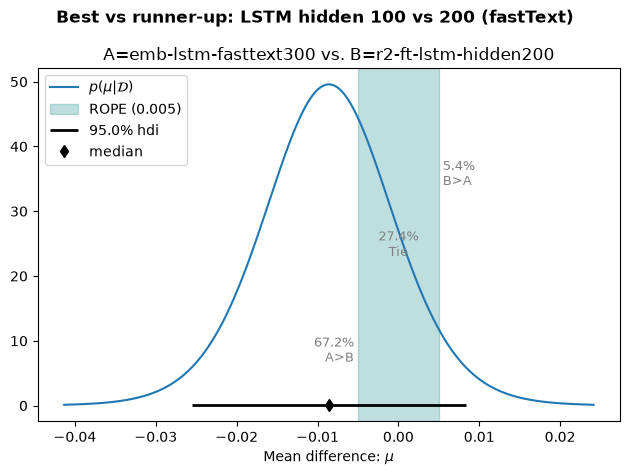

LSTM vs embed-and-pool (fastText):  P(A wins)=0.921  P(tie)=0.063  P(B wins)=0.016


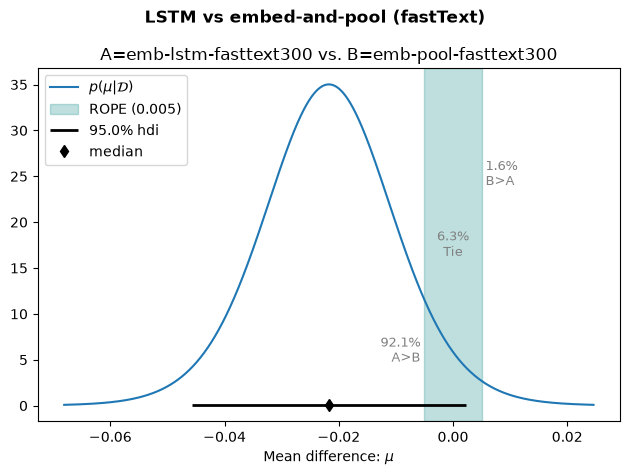

Embedding model: GloVe 50d vs fastText 300d (LSTM):  P(A wins)=0.000  P(tie)=0.000  P(B wins)=1.000


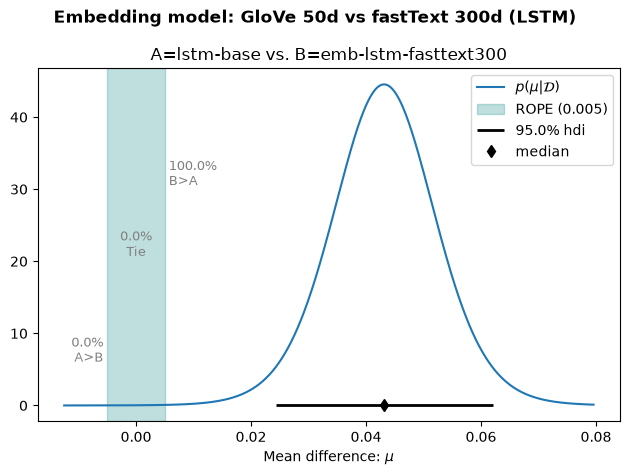

Frozen vs trainable embeddings (LSTM, fastText):  P(A wins)=1.000  P(tie)=0.000  P(B wins)=0.000


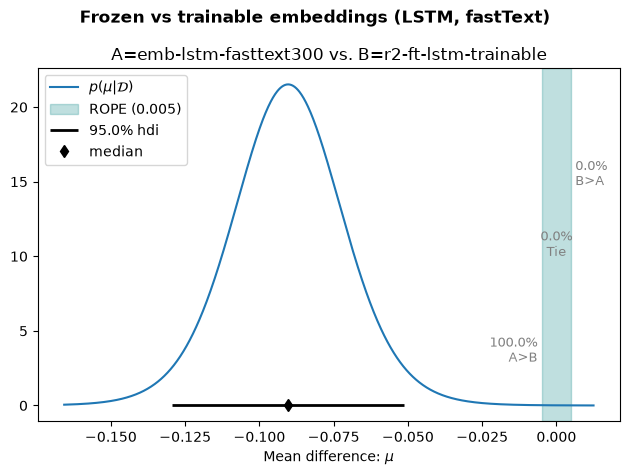

In [14]:
# Posteriors for a selection of comparisons (for the slides / blog)
selected = [
    ("Best vs runner-up: LSTM hidden 100 vs 200 (fastText)",  "emb-lstm-fasttext300", "r2-ft-lstm-hidden200"),
    ("LSTM vs embed-and-pool (fastText)",                     "emb-lstm-fasttext300", "emb-pool-fasttext300"),
    ("Embedding model: GloVe 50d vs fastText 300d (LSTM)",    "lstm-base",            "emb-lstm-fasttext300"),
    ("Frozen vs trainable embeddings (LSTM, fastText)",       "emb-lstm-fasttext300", "r2-ft-lstm-trainable"),
]

for title, a, b in selected:
    r, posterior = compare(a, b)
    print(f"{title}:  P(A wins)={r['P(A wins)']:.3f}  P(tie)={r['P(tie)']:.3f}  P(B wins)={r['P(B wins)']:.3f}")
    _ = posterior.plot(ROPE)
    plt.gcf().suptitle(title, fontsize=12, fontweight="bold")   # readable comparison above the plot
    plt.tight_layout()
    plt.show()

## Question 6: Error analysis (final system on the test set)
Final system: LSTM + fastText 300d (frozen), hidden 100. Its 15 models (3 seeds × 5 folds) each predicted the 1504 test texts.
For every text we compute the share of the 15 models that predicted it correctly, and relate that to features of the text.

In [15]:
from project1.data import load_data, EMOTIONS

final = json.load(open(MODAL_DIR / "test_final.json"))
dataset, outcome_space = load_data(test_size=0.2, seed=0)      # same split as on Modal
test_texts = list(dataset["test"]["text"])
train_texts = list(dataset["train"]["text"])

labels = np.array(final["test_labels"])                       # shape [1504]
preds = np.array(final["test_preds"])                         # shape [15 models, 1504]
assert len(test_texts) == len(labels) == preds.shape[1]

# share of the 15 models that got each text right (0 = always wrong, 1 = always right)
correct = (preds == labels).mean(axis=0)
# majority vote of the 15 models, for the confusion matrix
majority = np.array([np.bincount(col, minlength=len(EMOTIONS)).argmax() for col in preds.T])

print(f"Mean test accuracy over the 15 models: {correct.mean():.4f}")
print(f"Majority-vote accuracy:                {(majority == labels).mean():.4f}")

Mean test accuracy over the 15 models: 0.5828
Majority-vote accuracy:                0.6011


In [23]:
import os, certifi
os.environ["SSL_CERT_FILE"] = certifi.where()   # use certifi's certificates for downloads

import nltk
nltk.download("cmudict")
nltk.download("punkt_tab")

[nltk_data] Downloading package cmudict to /Users/eline/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.
[nltk_data] Downloading package punkt_tab to /Users/eline/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [24]:
import textstat

table = []
systems = {"lstm-fasttext": 0}     # our final system
items = dict()

for model_id, model_preds in enumerate(preds):     # 15 models = 3 seeds x 5 folds
    run, fold = divmod(model_id, 5)
    for i in range(len(model_preds)):
        item = i
        item_id = items.get(item, None)
        if item_id is None:
            item_id = len(items)
            items[item] = item_id

        x = test_texts[i]
        y_ = model_preds[i]
        y = labels[i]

        table.append([
            "lstm-fasttext",
            item,
            systems["lstm-fasttext"],
            item_id,
            run,
            fold,
            y,
            y_,
            int(y == y_),   # correctness flag
            textstat.lexicon_count(x),
            textstat.flesch_reading_ease(x),
            textstat.reading_time(x),
            textstat.flesch_kincaid_grade(x)
        ])

df = pd.DataFrame(table, columns=['system', 'item', 'system_id', 'item_id', 'run', 'fold', 'label', 'pred', 'correct', 'lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade'])
df

,system,item,system_id,item_id,run,fold,label,pred,correct,lexicon_count,flesch_reading_ease,reading_time,flesch_kincaid_grade
0,lstm-fasttext,0,0,0,0,0,0,0,1,14,65.725000,0.89609,7.570000
1,lstm-fasttext,1,0,1,0,0,4,4,1,43,89.979690,2.37978,4.269767
2,lstm-fasttext,2,0,2,0,0,5,5,1,41,89.792602,2.18881,4.130244
3,lstm-fasttext,3,0,3,0,0,2,5,0,14,71.767857,0.94016,6.727143
4,lstm-fasttext,4,0,4,0,0,5,6,0,22,53.759545,1.39555,11.226364
...,...,...,...,...,...,...,...,...,...,...,...,...,...
22555,lstm-fasttext,1499,0,1499,2,4,6,3,0,6,102.045000,0.38194,0.516667
22556,lstm-fasttext,1500,0,1500,2,4,4,3,0,62,77.124839,3.37870,10.203226
22557,lstm-fasttext,1501,0,1501,2,4,6,5,0,16,53.120000,1.04299,9.825000
22558,lstm-fasttext,1502,0,1502,2,4,2,5,0,36,82.815000,1.99784,6.180000


In [30]:
# Extra features from the "Features for analysis" tips: rare and unknown words (counted on the training texts)
import re
from collections import Counter

def words(text):
    return re.findall(r"[a-z']+", text.lower())

train_counts = Counter(w for t in train_texts for w in words(t))

def rare_word_features(text):
    ws = words(text)
    n_unseen = sum(train_counts[w] == 0 for w in ws)                        # words never seen in training
    mean_log_freq = np.mean([np.log1p(train_counts[w]) for w in ws]) if ws else 0.0   # low = rare words
    return n_unseen, mean_log_freq

extra = np.array([rare_word_features(t) for t in test_texts])                # one row per test text
df["n_unseen_words"] = extra[df["item"].to_numpy(), 0]
df["mean_log_freq"] = extra[df["item"].to_numpy(), 1]
df[["n_unseen_words", "mean_log_freq"]].describe()

,n_unseen_words,mean_log_freq
count,22560.000000,22560.000000
mean,0.644282,5.675217
std,1.039372,0.653354
min,0.000000,0.693147
25%,0.000000,5.326317
50%,0.000000,5.784545
75%,1.000000,6.119542
max,8.000000,7.599016


In [31]:
import part2.analysis

mcmc = part2.analysis.fit_bda_model(
    num_systems=len(systems),
    sys_id=df['system_id'].to_numpy(),
    features=np.hstack(
        [
            part2.analysis.one_hot(df['pred'].to_numpy(), len(EMOTIONS)),
            df[['lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade', 'n_unseen_words', 'mean_log_freq']].to_numpy()
        ]
    ),
    correctness=df['correct'].to_numpy(),
    num_chains=2
)
mcmc.print_summary()

sample: 100%|██████████| 2000/2000 [03:42<00:00,  8.98it/s, 511 steps of size 1.01e-02. acc. prob=0.94] 


                   mean       std    median      5.0%     95.0%     n_eff     r_hat
  global_mean      0.24      1.11      0.29     -1.66      2.07   1041.45      1.00
 sys_shift[0]      0.11      1.11      0.07     -1.65      2.07   1041.22      1.00
       w[0,0]      0.20      0.25      0.22     -0.17      0.59    390.04      1.01
       w[0,1]      0.18      0.26      0.19     -0.21      0.58    386.57      1.01
       w[0,2]     -0.19      0.28     -0.18     -0.60      0.25    388.12      1.01
       w[0,3]      0.15      0.25      0.16     -0.22      0.56    386.94      1.01
       w[0,4]      0.04      0.26      0.05     -0.34      0.46    387.58      1.01
       w[0,5]     -0.15      0.25     -0.14     -0.52      0.23    386.46      1.01
       w[0,6]     -0.18      0.24     -0.17     -0.55      0.19    390.01      1.01
       w[0,7]      0.09      0.10      0.08     -0.09      0.23   1086.54      1.00
       w[0,8]     -0.17      0.04     -0.17     -0.23     -0.11   1303.43  

In [32]:
posterior = mcmc.get_samples()
print("Weight samples:", posterior["w"].shape)
print("System shift samples:", posterior["sys_shift"].shape)
print("Divergences:", int(mcmc.get_extra_fields()["diverging"].sum()))

Weight samples: (2000, 1, 13)
System shift samples: (2000, 1)
Divergences: 0


In [33]:
import arviz as az

posterior_data = part2.analysis.posterior_to_arviz(
    mcmc,
    system_names=[name for name, _ in sorted(systems.items(), key=lambda pair: pair[1])],
    feature_names=[f"pred:{n}" for n in EMOTIONS] + ['lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade', 'n_unseen_words', 'mean_log_freq']
)
az_stats_params = {'point_estimate': 'median', 'ci_kind': 'hdi', 'ci_probs': (0.5, 0.95)}

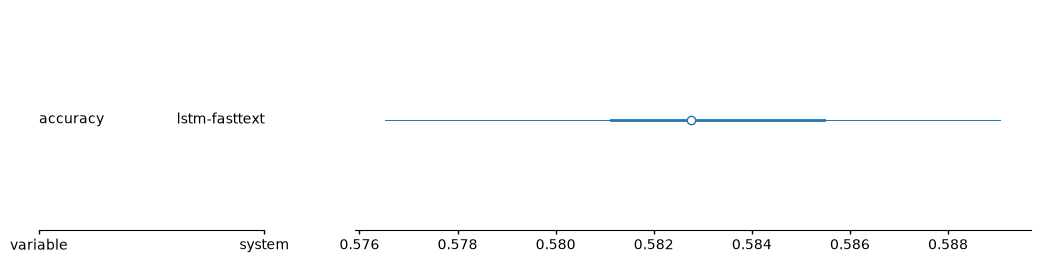

In [34]:
az.plot_forest(
    posterior_data,
    var_names=['accuracy'],
    combined=True,
    **az_stats_params
)

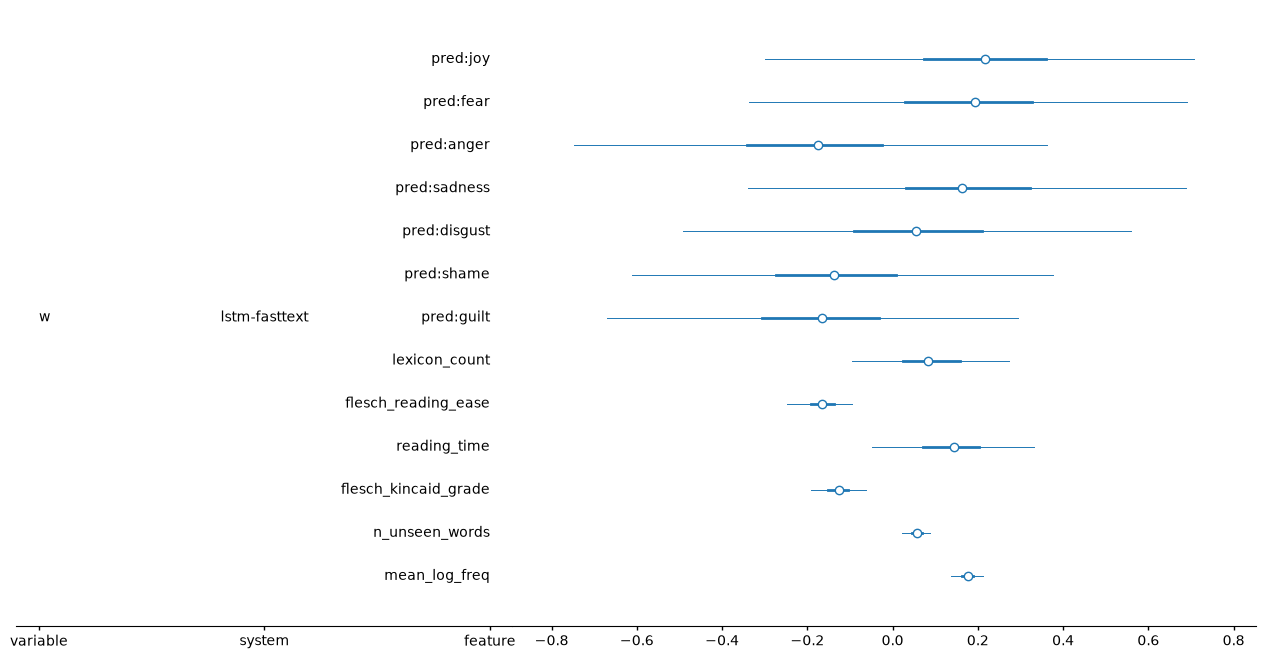

In [35]:
az.plot_forest(
    posterior_data,
    var_names=['w'],
    combined=True,
    shade_label="system",
    figure_kwargs={
        "figsize": (16, 8),
        "width_ratios": [2, 3],
        "layout": "none",
    },
    **az_stats_params,
)

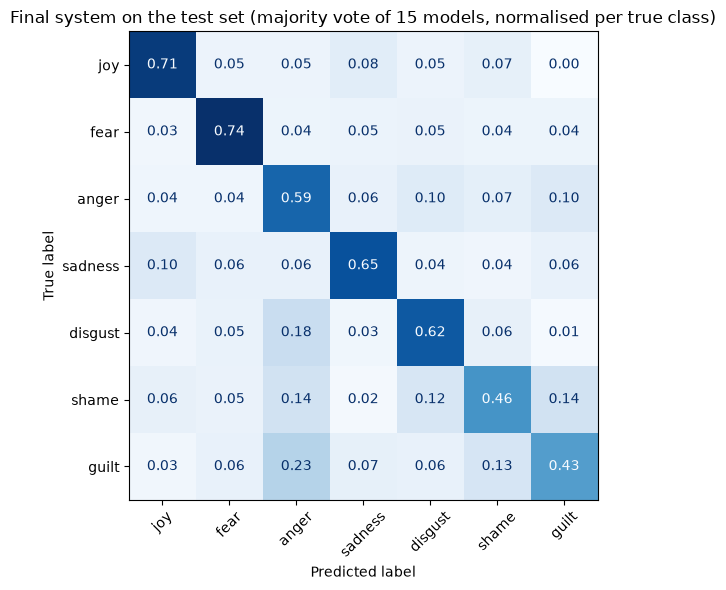

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    labels, majority, labels=list(range(len(EMOTIONS))), display_labels=EMOTIONS,
    normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Final system on the test set (majority vote of 15 models, normalised per true class)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

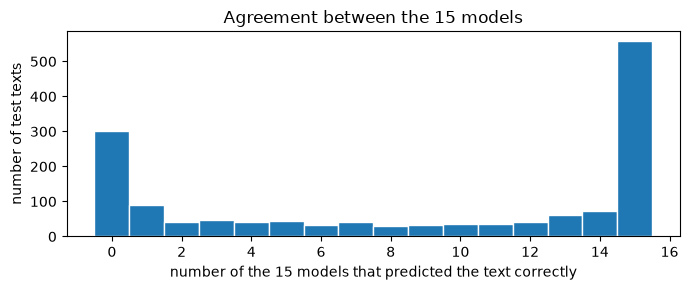

Always right (15/15): 37.1% of texts
Always wrong (0/15):  19.9% of texts
Uncertain (5-10/15):  14.4% of texts

Examples that all 15 models got wrong:
- true: anger    predicted (majority): shame    When I discovered that the people I trusted most were talking behind my back.
- true: anger    predicted (majority): sadness  I am one of four directors of a company. We inherited land held by our family - ours is the 5th generation. A "democratic" decision was made to stap-bank an area of mangroves.
- true: shame    predicted (majority): sadness  The first time that I caressed a girl, I was about thirteen and she was eighteen. I noticed that it did not affect her at all.
- true: fear     predicted (majority): anger    When I was treated improperly by someone.
- true: anger    predicted (majority): fear     Once I saw some children hunting a cat to death.
- true: sadness  predicted (majority): joy      I was to meet a girl in a discotheque. She was very pretty and I was very happy. But she 

In [20]:
n_correct = (preds == labels).sum(axis=0)        # 0..15 models correct per text

plt.figure(figsize=(7, 3))
plt.hist(n_correct, bins=np.arange(17) - 0.5, edgecolor="white")
plt.xlabel("number of the 15 models that predicted the text correctly"); plt.ylabel("number of test texts")
plt.title("Agreement between the 15 models"); plt.tight_layout(); plt.show()

print(f"Always right (15/15): {(n_correct == 15).mean():.1%} of texts")
print(f"Always wrong (0/15):  {(n_correct == 0).mean():.1%} of texts")
print(f"Uncertain (5-10/15):  {((n_correct >= 5) & (n_correct <= 10)).mean():.1%} of texts")

print("\nExamples that all 15 models got wrong:")
for i in np.where(n_correct == 0)[0][:8]:
    print(f"- true: {EMOTIONS[labels[i]]:<8} predicted (majority): {EMOTIONS[majority[i]]:<8} {' '.join(test_texts[i].split())}")